Patient                               Score Tier       Result
Patient 1 — Expected: Healthy          0.0%  Low        🟢 Non-Diabetic
Patient 2 — Expected: Healthy          0.0%  Low        🟢 Non-Diabetic
Patient 3 — Expected: Diabetic       100.0%  Critical   🔴 Diabetic
Patient 4 — Expected: Diabetic       100.0%  Critical   🔴 Diabetic

Patient 1 — Expected: Healthy
--------------------------------------------------
  HbA1c_level               -6.2831  ↓ risk
  blood_glucose_level       -4.8444  ↓ risk
  age                       -0.6127  ↓ risk

Patient 2 — Expected: Healthy
--------------------------------------------------
  HbA1c_level               -6.1177  ↓ risk
  blood_glucose_level       -4.9900  ↓ risk
  bmi                       -0.2927  ↓ risk

Patient 3 — Expected: Diabetic
--------------------------------------------------
  HbA1c_level               +7.2015  ↑ risk
  hypertension              +0.2302  ↑ risk
  age                       -0.1130  ↓ risk

Patient 4 — Expect

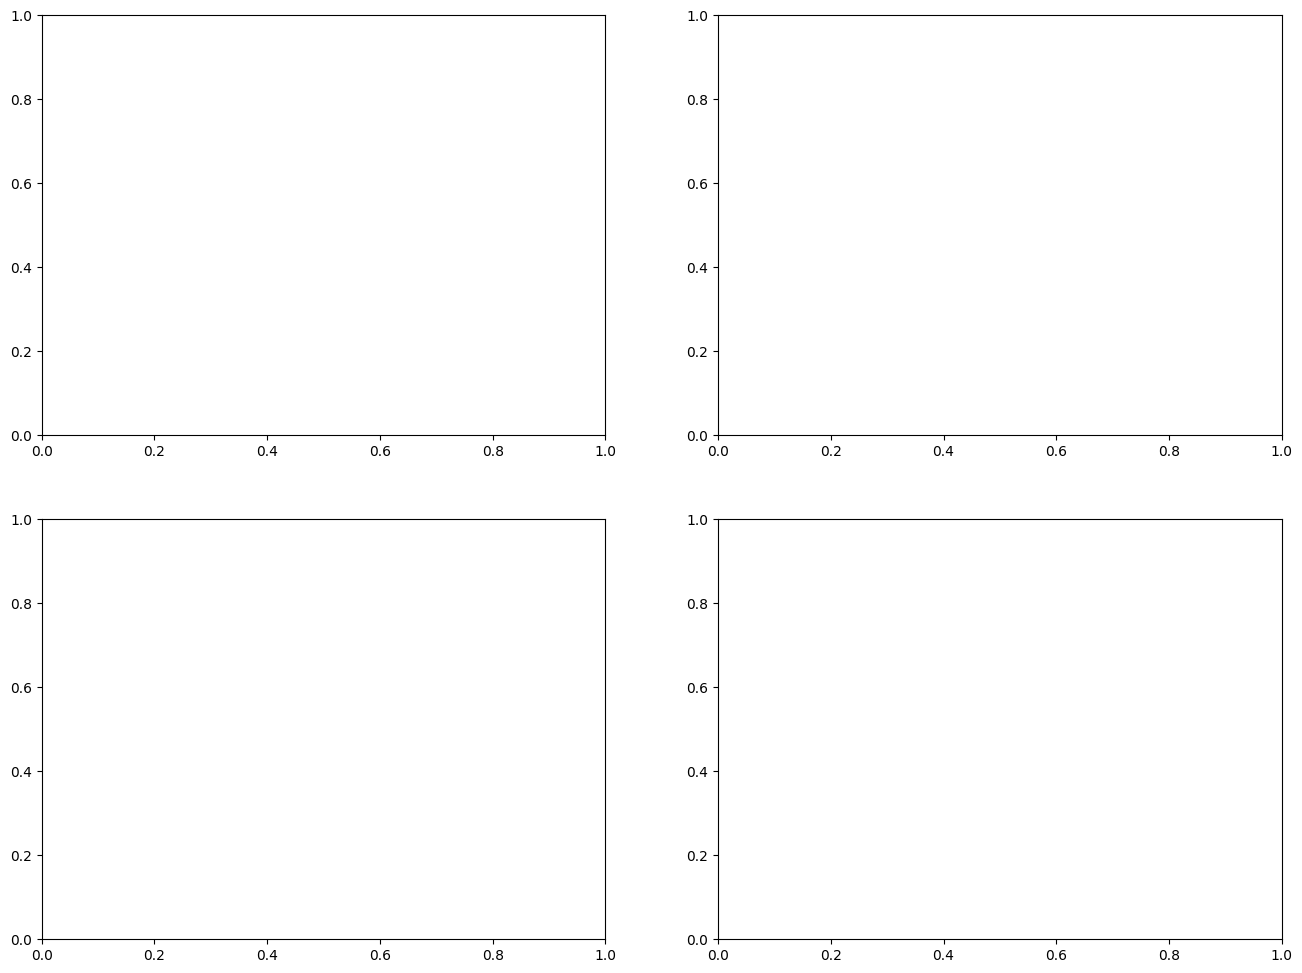

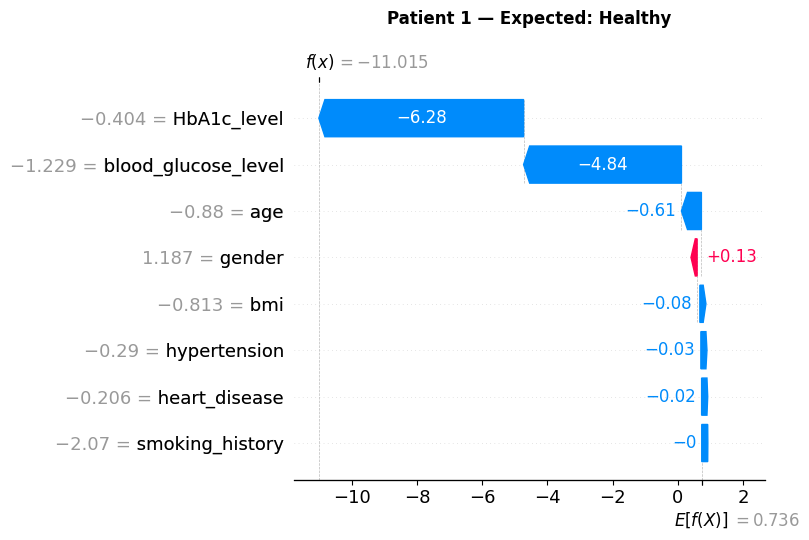

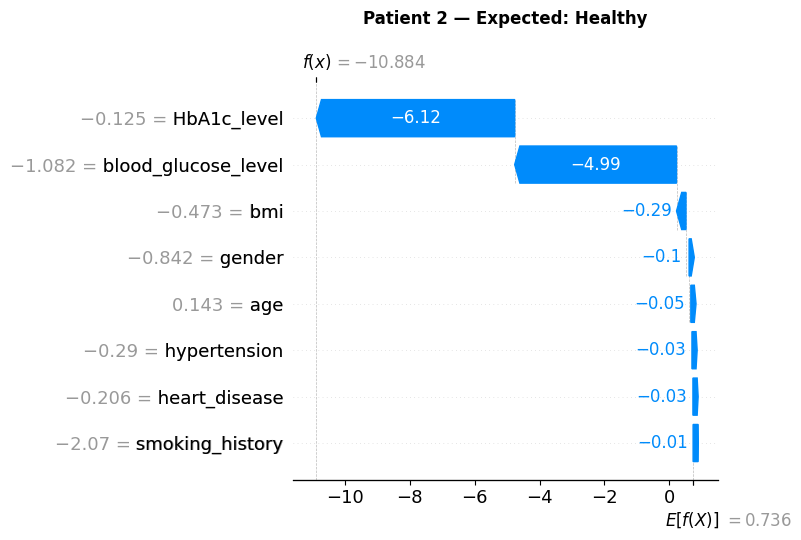

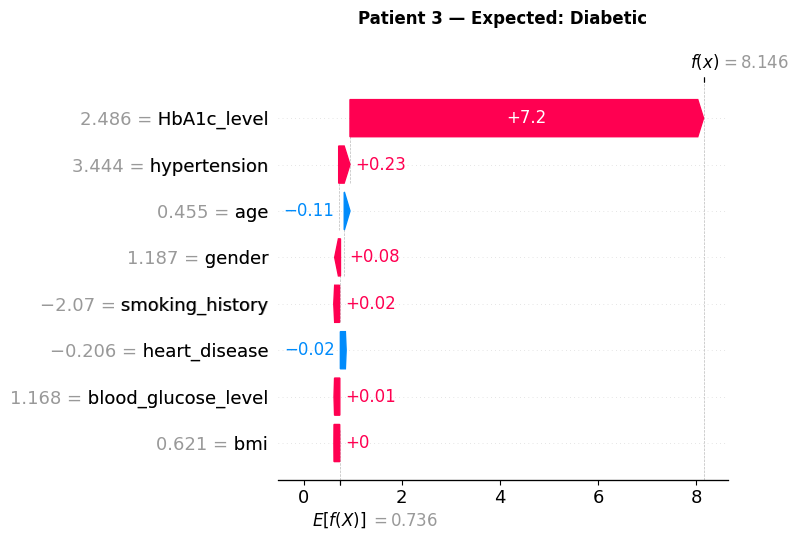

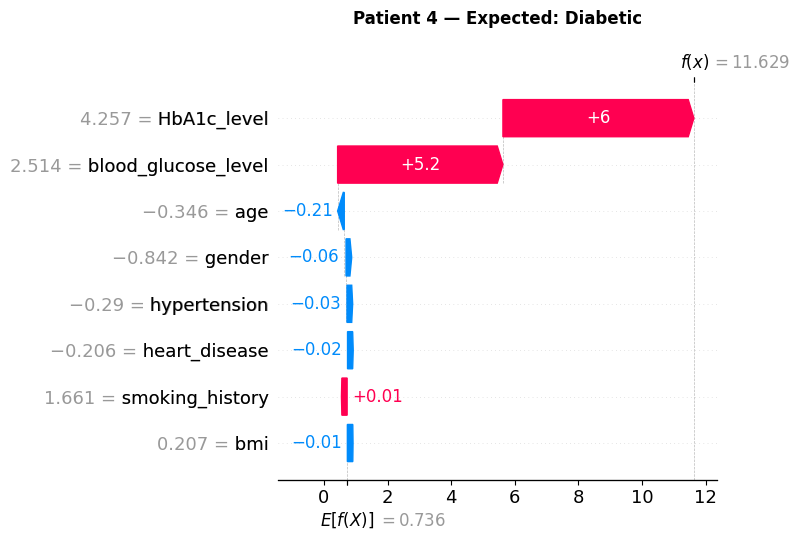

In [19]:
import pandas as pd
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt
import os
os.makedirs('results', exist_ok=True)

# ── Load ──────────────────────────────────────────────────────────────────────
model     = joblib.load('xgb_diabetes.pkl')
scaler    = joblib.load('scaler.pkl')
threshold = joblib.load('xgb_threshold.pkl')
explainer = joblib.load('shap_explainer.pkl')

FEATURES = list(scaler.feature_names_in_)

# ── Patient data ──────────────────────────────────────────────────────────────
# gender:          0=Male, 1=Female
# hypertension:    BP >= 140/90 → 1
# smoking_history: 0=Never, 1=Former, 2=Current

patients = [
    {
        "name":                "Patient 1 — Expected: Healthy",
        "age":                 22,
        "gender":              1,      # Female
        "bmi":                 21.8,
        "HbA1c_level":         5.1,
        "blood_glucose_level": 88,
        "hypertension":        0,      # 110/70 → normal
        "heart_disease":       0,
        "smoking_history":     0       # No smoking
    },
    {
        "name":                "Patient 2 — Expected: Healthy",
        "age":                 45,
        "gender":              0,      # Male
        "bmi":                 24.1,
        "HbA1c_level":         5.4,
        "blood_glucose_level": 94,
        "hypertension":        0,      # 122/78 → normal
        "heart_disease":       0,
        "smoking_history":     0
    },
    {
        "name":                "Patient 3 — Expected: Diabetic",
        "age":                 52,
        "gender":              1,      # Female
        "bmi":                 31.5,
        "HbA1c_level":         8.2,
        "blood_glucose_level": 186,
        "hypertension":        1,      # 145/90 → hypertensive
        "heart_disease":       0,
        "smoking_history":     0
    },
    {
        "name":                "Patient 4 — Expected: Diabetic",
        "age":                 34,
        "gender":              0,      # Male
        "bmi":                 28.7,
        "HbA1c_level":         10.1,
        "blood_glucose_level": 241,
        "hypertension":        0,      # 138/86 → borderline, not hypertensive
        "heart_disease":       0,
        "smoking_history":     2       # Current smoker
    }
]

# ── Risk tier ─────────────────────────────────────────────────────────────────
def get_risk_tier(prob, hba1c=None, glucose=None):
    # Prediabetic override — applied before ML score
    if hba1c is not None and glucose is not None:
        if 5.7 <= hba1c < 6.5 and 100 <= glucose < 126:
            return "Prediabetic ⚠️"
    if prob < 0.3:    return "Low"
    elif prob < 0.5:  return "Moderate"
    elif prob < 0.75: return "High"
    else:             return "Critical"

# ── Run all patients ──────────────────────────────────────────────────────────
results = []

for p in patients:
    name = p.pop("name")
    df     = pd.DataFrame([p])[FEATURES]
    scaled = scaler.transform(df)

    prob       = float(model.predict_proba(scaled)[0][1])
    prediction = int(prob >= threshold)

    shap_vals      = explainer.shap_values(scaled)[0]
    feature_impact = dict(zip(FEATURES, shap_vals))
    top_factors    = sorted(feature_impact.items(),
                            key=lambda x: abs(x[1]),
                            reverse=True)[:3]

    results.append({
        "name":        name,
        "prob":        prob,
        "prediction":  prediction,
        "tier":        get_risk_tier(prob),
        "top_factors": top_factors,
        "shap_vals":   shap_vals,
        "scaled":      scaled
    })

    p["name"] = name  # restore

# ── Print summary table ───────────────────────────────────────────────────────
print("=" * 70)
print(f"{'Patient':<35} {'Score':>7} {'Tier':<10} {'Result'}")
print("=" * 70)
for r in results:
    result_label = "🔴 Diabetic" if r["prediction"] == 1 else "🟢 Non-Diabetic"
    print(f"{r['name']:<35} {r['prob']*100:>6.1f}%  {r['tier']:<10} {result_label}")
print("=" * 70)

# ── Print SHAP top factors per patient ────────────────────────────────────────
for r in results:
    print(f"\n{r['name']}")
    print("-" * 50)
    for feature, value in r["top_factors"]:
        direction = "↑ risk" if value > 0 else "↓ risk"
        print(f"  {feature:<25} {value:+.4f}  {direction}")

# ── Waterfall plots for all 4 ─────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, r in enumerate(results):
    plt.figure(figsize=(10, 5))
    shap.waterfall_plot(
        shap.Explanation(
            values=r["shap_vals"],
            base_values=explainer.expected_value,
            data=r["scaled"][0],
            feature_names=FEATURES
        ),
        show=False
    )
    plt.title(r["name"], fontsize=12, fontweight='bold', pad=20)
    plt.tight_layout()
    plt.savefig(f'results/shap_patient_{i+1}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()


Patient                                    Score Tier         Result
Patient 5 — Expected: Prediabetic           0.1%  Prediabetic ⚠️ 🟢 Non-Diabetic
Patient 6 — Expected: Prediabetic           0.0%  Prediabetic ⚠️ 🟢 Non-Diabetic

Patient 5 — Expected: Prediabetic
--------------------------------------------------
  blood_glucose_level       -6.9009  ↓ risk
  HbA1c_level               -1.1567  ↓ risk
  age                       -0.1292  ↓ risk

Patient 6 — Expected: Prediabetic
--------------------------------------------------
  blood_glucose_level       -7.2011  ↓ risk
  HbA1c_level               -1.2743  ↓ risk
  bmi                       +0.1752  ↑ risk


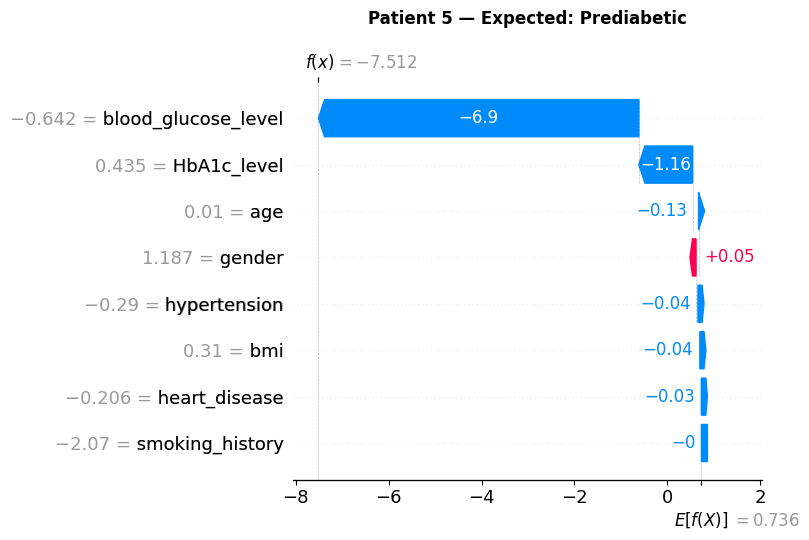

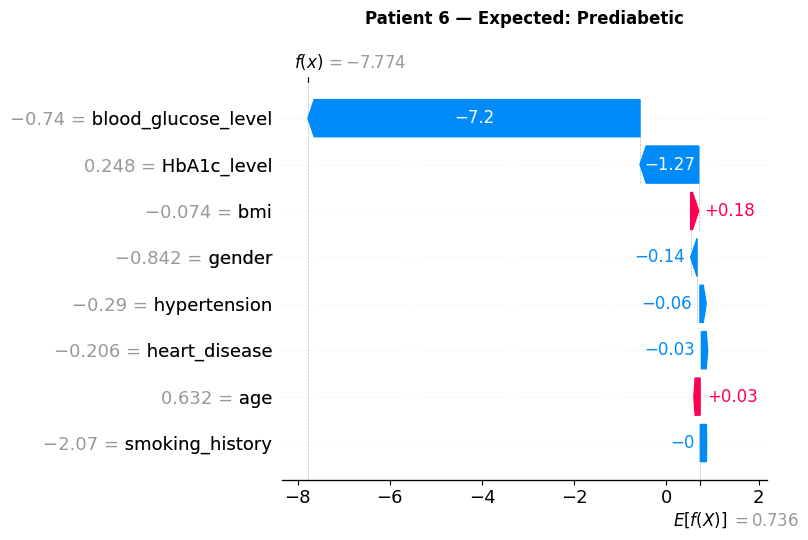

In [21]:
patients_new = [
    {
        "name":                "Patient 5 — Expected: Prediabetic",
        "age":                 42,
        "gender":              1,      # Female
        "bmi":                 29.4,
        "HbA1c_level":         6.0,
        "blood_glucose_level": 112,
        "hypertension":        0,      # 132/84 → borderline, not hypertensive
        "heart_disease":       0,
        "smoking_history":     0       # Never
    },
    {
        "name":                "Patient 6 — Expected: Prediabetic",
        "age":                 56,
        "gender":              0,      # Male
        "bmi":                 26.8,
        "HbA1c_level":         5.8,
        "blood_glucose_level": 108,
        "hypertension":        0,      # 128/82 → borderline, not hypertensive
        "heart_disease":       0,
        "smoking_history":     0       # Never
    }
]

results_new = []

for p in patients_new:
    name = p.pop("name")
    df     = pd.DataFrame([p])[FEATURES]
    scaled = scaler.transform(df)

    prob       = float(model.predict_proba(scaled)[0][1])
    prediction = int(prob >= threshold)

    shap_vals      = explainer.shap_values(scaled)[0]
    feature_impact = dict(zip(FEATURES, shap_vals))
    top_factors    = sorted(feature_impact.items(),
                            key=lambda x: abs(x[1]),
                            reverse=True)[:3]

    results_new.append({
        "name":        name,
        "prob":        prob,
        "prediction":  prediction,
        "tier": get_risk_tier(
            prob,
            hba1c=p.get("HbA1c_level"),
            glucose=p.get("blood_glucose_level")),
        "top_factors": top_factors,
        "shap_vals":   shap_vals,
        "scaled":      scaled
    })

    p["name"] = name

# ── Summary ───────────────────────────────────────────────────────────────────
print("=" * 70)
print(f"{'Patient':<40} {'Score':>7} {'Tier':<12} {'Result'}")
print("=" * 70)
for r in results_new:
    label = "🔴 Diabetic" if r["prediction"] == 1 else "🟢 Non-Diabetic"
    print(f"{r['name']:<40} {r['prob']*100:>6.1f}%  {r['tier']:<12} {label}")
print("=" * 70)

# ── SHAP top factors ──────────────────────────────────────────────────────────
for r in results_new:
    print(f"\n{r['name']}")
    print("-" * 50)
    for feature, value in r["top_factors"]:
        direction = "↑ risk" if value > 0 else "↓ risk"
        print(f"  {feature:<25} {value:+.4f}  {direction}")

# ── Waterfall plots ───────────────────────────────────────────────────────────
for i, r in enumerate(results_new):
    plt.figure(figsize=(10, 5))
    shap.waterfall_plot(
        shap.Explanation(
            values=r["shap_vals"],
            base_values=explainer.expected_value,
            data=r["scaled"][0],
            feature_names=FEATURES
        ),
        show=False
    )
    plt.title(r["name"], fontsize=12, fontweight='bold', pad=20)
    plt.tight_layout()
    plt.savefig(f'results/shap_patient_{i+5}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

Patient                               Score Tier            Result
Patient — Expected: Moderate         100.0%  Critical        🔴 Diabetic
Patient — Expected: High             100.0%  Critical        🔴 Diabetic


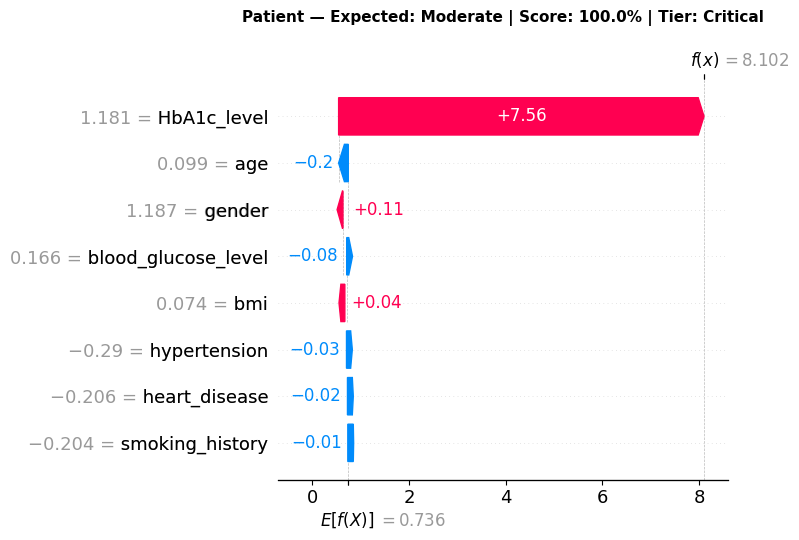

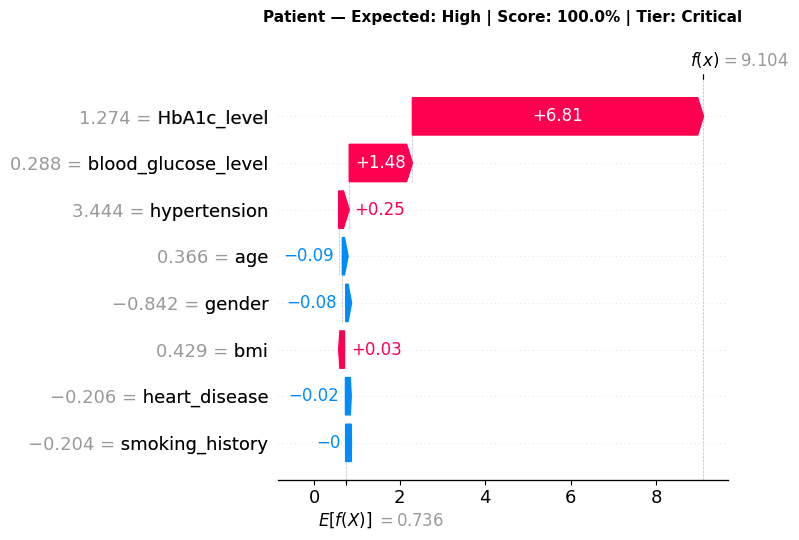

In [23]:
patients_tiers = [
   # Moderate — lower HbA1c slightly, keep glucose borderline
{
    "name":                "Patient — Expected: Moderate",
    "age":                 44,
    "gender":              1,
    "bmi":                 27.8,
    "HbA1c_level":         6.8,      # just above diabetic threshold
    "blood_glucose_level": 145,      # elevated but not extreme
    "hypertension":        0,
    "heart_disease":       0,
    "smoking_history":     1
},

# High — reduce HbA1c and glucose from Critical range
{
    "name":                "Patient — Expected: High",
    "age":                 50,
    "gender":              0,
    "bmi":                 30.2,
    "HbA1c_level":         6.9,      # just above threshold
    "blood_glucose_level": 150,      # elevated but not extreme  
    "hypertension":        1,
    "heart_disease":       0,
    "smoking_history":     1
},
]

results_tiers = []

for p in patients_tiers:
    name = p.pop("name")
    df     = pd.DataFrame([p])[FEATURES]
    scaled = scaler.transform(df)

    prob       = float(model.predict_proba(scaled)[0][1])
    prediction = int(prob >= threshold)

    shap_vals      = explainer.shap_values(scaled)[0]
    feature_impact = dict(zip(FEATURES, shap_vals))
    top_factors    = sorted(feature_impact.items(),
                            key=lambda x: abs(x[1]),
                            reverse=True)[:3]

    tier = get_risk_tier(
        prob,
        hba1c=p.get("HbA1c_level"),
        glucose=p.get("blood_glucose_level")
    )

    results_tiers.append({
        "name":        name,
        "prob":        prob,
        "prediction":  prediction,
        "tier":        tier,
        "top_factors": top_factors,
        "shap_vals":   shap_vals,
        "scaled":      scaled
    })

    p["name"] = name

# ── Summary ───────────────────────────────────────────────────────────────────
print("=" * 70)
print(f"{'Patient':<35} {'Score':>7} {'Tier':<15} {'Result'}")
print("=" * 70)
for r in results_tiers:
    label = "🔴 Diabetic" if r["prediction"] == 1 else "🟢 Non-Diabetic"
    print(f"{r['name']:<35} {r['prob']*100:>6.1f}%  {r['tier']:<15} {label}")
print("=" * 70)

# ── Waterfall plots ───────────────────────────────────────────────────────────
for i, r in enumerate(results_tiers):
    plt.figure(figsize=(10, 5))
    shap.waterfall_plot(
        shap.Explanation(
            values=r["shap_vals"],
            base_values=explainer.expected_value,
            data=r["scaled"][0],
            feature_names=FEATURES
        ),
        show=False
    )
    plt.title(f"{r['name']} | Score: {r['prob']*100:.1f}% | Tier: {r['tier']}",
              fontsize=11, fontweight='bold', pad=20)
    plt.tight_layout()
    plt.savefig(f'results/shap_tier_{i+1}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()